# Build a Basic Chatbot with Langgraph(Graph Api) 

In [29]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [30]:
class State(TypedDict):
    # messages have the type "list".the 'add_messages' function 
    # in the annnotation defines how this state key should be updated 
    # (in this case, it appends messages to the list ,rather than overwriting them)
    messages:Annotated[list,add_messages]


graph_builder = StateGraph(State)

In [31]:
graph_builder

In [32]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [33]:
from langchain_groq  import ChatGroq
from langchain.chat_models import init_chat_model


model=init_chat_model(
    "qwen/qwen3.8-27b",
    model_provider="groq",
    temperature=0,
    max_tokens=512
    
)



In [34]:
llm =ChatGroq(model="qwen/qwen3.8-27b")

In [35]:
## Node Functionality 
def chatbot (state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [36]:
graph_builder =StateGraph(State)
## Adding Node 
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges 
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

##compile the graph 

graph =graph_builder.compile()

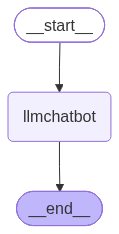

In [37]:
## Visulaize the graph 
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [38]:
response=graph.invoke({"messages":"Hii"})

In [39]:
response["messages"][-1].content

'Hi! How can I help you today?'

In [40]:
for event in graph.stream({"messages":"hii how are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing well, thank you for asking. How are you?

Is there anything specific I can help you with today?


# Chatbot With Tool

In [41]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("what is langgraph ")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [42]:
## Custom function 
def multiply (a:int,b:int)->int:
    """Multiply a and b
    Args:
      a(int):frist int 
      b(int):second int
    Returns:
       int:output int
    """
    return a*b


In [43]:
tools=[tool,multiply]

In [44]:
llm_with_tool=llm.bind_tools(tools)

In [45]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001762F3EEF60>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001762F3EC170>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine op

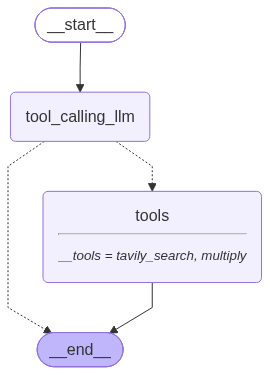

In [46]:
## Stategraph 
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition 
def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}
## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

### Add Edges 
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is tool call -> tools_condition routes to tools 
    # If the latest Messages (result ) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools",END)

## compile the graph 
graph =builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [47]:
response=graph.invoke({"messages":"What is recent ai news "})

In [48]:
response['messages'][-1].content 

"Here is some recent AI news, though please note that I don't have access to real-time information. For the very latest developments, I recommend checking major tech news sources like TechCrunch, The Verge, or Ars Technica.\n\nThat said, here are some of the major themes and developments that have been dominating AI news in 2024-2025:\n\n1. **Large Language Model Advancements**: Major companies like OpenAI, Anthropic, Google, and Meta have been releasing increasingly capable models. OpenAI's GPT-4o and subsequent updates, Anthropic's Claude models, and Google's Gemini series have been at the forefront of this race.\n\n2. **AI Regulation**: Governments worldwide have been working on AI regulation frameworks. The EU AI Act is one of the most comprehensive regulatory frameworks, aiming to classify AI systems by risk level and impose corresponding requirements.\n\n3. **AI in the Workplace**: There's been significant discussion about how AI is transforming work, including concerns about job

In [49]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is recent ai news 
================================== Ai Message ==================================

Here is some recent AI news, though please note that I don't have access to real-time information. For the very latest developments, I recommend checking major tech news sources like TechCrunch, The Verge, or Ars Technica.

That said, here are some of the major themes and developments that have been dominating AI news in 2024-2025:

1. **Large Language Model Advancements**: Major companies like OpenAI, Anthropic, Google, and Meta have been releasing increasingly capable models. OpenAI's GPT-4o and subsequent updates, Anthropic's Claude models, and Google's Gemini series have been at the forefront of this race.

2. **AI Regulation**: Governments worldwide have been working on AI regulation frameworks. The EU AI Act is one of the most comprehensive regulatory frameworks, aiming to classify AI systems by

In [50]:
response = graph.invoke({"messages":"what is 2 is mutliply by 3"})
response['messages'][-1].content 

'6'

In [51]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is 2 is mutliply by 3
================================== Ai Message ==================================
Tool Calls:
  multiply (hxbpbayp6)
 Call ID: hxbpbayp6
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [52]:
response = graph.invoke({"messages":"what is 2 is mutliply by 3 then multiply by 10"})
response['messages'][-1].content 

for m in response['messages']:
    m.pretty_print()



================================ Human Message =================================

what is 2 is mutliply by 3 then multiply by 10
================================== Ai Message ==================================

I'll calculate this step by step:

1. 2 × 3 = 6
2. 6 × 10 = 60

Let me verify with the multiply function:
Tool Calls:
  multiply (dkdc9xs13)
 Call ID: dkdc9xs13
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


# React agent arch

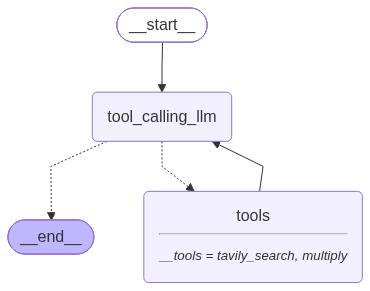

In [53]:
## Stategraph 
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition 
def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}
## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

### Add Edges 
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is tool call -> tools_condition routes to tools 
    # If the latest Messages (result ) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","tool_calling_llm")

## compile the graph 
graph =builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [54]:
response = graph.invoke({"messages":"give me recent ai news then multiply by 10"})
response['messages'][-1].content 

for m in response['messages']:
    m.pretty_print()



================================ Human Message =================================

give me recent ai news then multiply by 10
================================== Ai Message ==================================

Here is some recent AI news:

1. **OpenAI Releases GPT-4o**: OpenAI has launched GPT-4o, a new multimodal model that can understand and respond to text, images, and audio in real-time.
2. **Google Advances Gemini**: Google has been making significant strides with its Gemini models, focusing on improving their reasoning capabilities and integration across Google's ecosystem.
3. **Microsoft's AI Integration**: Microsoft continues to integrate AI deeply into its products, including Copilot in Office 365 and Azure OpenAI services.
4. **Rise of AI in Healthcare**: Major healthcare institutions are increasingly adopting AI for diagnostic imaging, drug discovery, and personalized medicine.
5. **Ethical AI Debates**: Ongoing discussions and regulatory efforts are focused on ensuring AI syst

# Adding Memory in Agentic graph 

In [56]:
response = graph.invoke({"messages":"my name is  ak "})
response['messages'][-1].content 

for m in response['messages']:
    m.pretty_print()



================================ Human Message =================================

my name is  ak 
================================== Ai Message ==================================

Nice to meet you, ak! How can I help you today?


In [57]:
response = graph.invoke({"messages":"what is my name "})
response['messages'][-1].content 

for m in response['messages']:
    m.pretty_print()



================================ Human Message =================================

what is my name 
================================== Ai Message ==================================

I don't know your name. I'm an AI assistant and don't have access to personal information about you unless you share it with me. Feel free to tell me your name if you'd like me to address you by it!


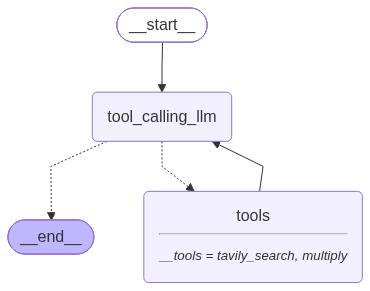

In [65]:
## Stategraph 
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import  MemorySaver

memory=MemorySaver()

## Node definition 
def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}
## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

### Add Edges 
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is tool call -> tools_condition routes to tools 
    # If the latest Messages (result ) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","tool_calling_llm")

## compile the graph 
graph =builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))


In [66]:
config={"configurable":{"thread_id":"1"}}
graph.invoke({"messages":"Hii my name is krish "},config=config )
response

{'messages': [HumanMessage(content='what is my name ', additional_kwargs={}, response_metadata={}, id='d0c39193-d69e-41c5-8019-330112fa83b3'),
  AIMessage(content="I don't know your name. I'm an AI assistant and don't have access to personal information about you unless you share it with me. Feel free to tell me your name if you'd like me to address you by it!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 1922, 'total_tokens': 1970, 'completion_time': 0.094897149, 'completion_tokens_details': None, 'prompt_time': 0.141110942, 'prompt_tokens_details': None, 'queue_time': 0.050018592, 'total_time': 0.236008091}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a2020e-626b-721a-8697-885ebd64b0b9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1922, 'output_tokens': 48, 'tota

In [67]:
response['messages'][-1].content

"I don't know your name. I'm an AI assistant and don't have access to personal information about you unless you share it with me. Feel free to tell me your name if you'd like me to address you by it!"

In [ ]:
response=graph.invoke({"messages":"Hey do you remember my name "},config=config)
response['messages'][-1].contentalue

'Yes, I remember your name! Your name is **Krish**.'

# Streaming 

## Methods: .stream() and astream()
 - These methods are sync and async methods for streaming back results 
## Additional parameters in streaming modes for graph state 

- ### values :This stream the full state of the graph after each node  is called.
- ### Updates : This stream updates to the state of the graph after each node is called.

In [70]:
from langgraph.checkpoint.memory import  MemorySaver
memory=MemorySaver()

In [71]:
def superbot(state:State):
    return{"messages":[llm.invoke(state['messages'])]}

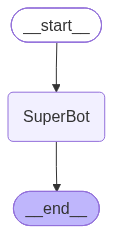

In [72]:
graph=StateGraph(State)

##Node 
graph.add_node("SuperBot",superbot)
##Edges 
graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile(checkpointer=memory)

## Display
from IPython.display import Image ,display 
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [74]:
## Invocation 

config={"configurable":{"thread_id":"1"}}

graph_builder.invoke({'messages':"Hi my name is ak and i like cricket "},config )

{'messages': [HumanMessage(content='Hi my name is ak and i like cricket ', additional_kwargs={}, response_metadata={}, id='8d1ec2e7-87ac-4138-8e3f-6070f6be3df5'),
  AIMessage(content='Hi Ak! It’s great to meet you. Cricket is definitely one of the most exciting sports in the world, especially with the fast-paced T20 format and the strategic depth of Test matches.\n\nWho is your favorite player or team? Do you prefer watching live matches or just following the highlights? 🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 21, 'total_tokens': 86, 'completion_time': 0.137876719, 'completion_tokens_details': None, 'prompt_time': 0.001216894, 'prompt_tokens_details': None, 'queue_time': 0.047552516, 'total_time': 0.139093613}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20244-90b5-737a-afdb-e05597a8

In [75]:
# create the thread 

config ={"configurable":{"thread_id":"3"}}

for chunk in graph_builder.stream({'messages':"Hi, My is Krish! It is great to hear that you like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Krish! It’s great to meet you.\n\nActually, I should clarify that I don’t have personal feelings or preferences, so I don’t "like" cricket in the way humans do. However, I am very knowledgeable about the sport! I can discuss rules, player statistics, match history, tactics, and famous moments with you.\n\nAre you a cricket fan? Is there a particular team, player, or recent match you’d like to chat about? 🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 98, 'prompt_tokens': 27, 'total_tokens': 125, 'completion_time': 0.190219521, 'completion_tokens_details': None, 'prompt_time': 0.001564994, 'prompt_tokens_details': None, 'queue_time': 0.047532756, 'total_time': 0.191784515}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20252-da1e-74d2-8fd1-cdb013ff4030-0', tool_call

In [76]:
# create the thread 

config ={"configurable":{"thread_id":"4"}}

for chunk in graph_builder.stream({'messages':"Hi, My is Krish! It is great to hear that you like cricket and also like football"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Krish! It’s great to meet you.\n\nI appreciate the compliment, but I should clarify: as an AI, I don’t personally "like" sports or have feelings. However, I have access to a vast amount of information about both cricket and football! I can discuss match statistics, player careers, rule nuances, or even help you analyze a recent game if you’re interested.\n\nSince you mentioned both, is there a specific match, team, or player you’d like to talk about? Or perhaps you’re debating which sport is more exciting? I’m happy to chat about either one! 🏏⚽', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 129, 'prompt_tokens': 31, 'total_tokens': 160, 'completion_time': 0.25864616, 'completion_tokens_details': None, 'prompt_time': 0.001855495, 'prompt_tokens_details': None, 'queue_time': 0.049315034, 'total_time': 0.260501655}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_

In [77]:
for chunk in graph_builder.stream({'messages':"Hi, My is Krish! It is great to hear that you like crickeand i also like footballt"},config,stream_mode="value"):
    print(chunk)

#### astream

In [79]:
# create the thread 

config ={"configurable":{"thread_id":"5"}}

for chunk in graph_builder.stream({'messages':"Hi, My is Krish! It is great to hear that you like cricket and also like football"},config,version="v2"):
    print(chunk)

{'type': 'updates', 'ns': (), 'data': {'SuperBot': {'messages': [AIMessage(content='Hi Krish! It’s great to meet you.\n\nI appreciate the sentiment, but I should clarify: as an AI, I don’t have personal feelings or hobbies, so I don’t actually *like* cricket or football. However, I certainly have access to a lot of information about both sports—including rules, history, statistics, and player details—if you’d like to chat about them!\n\nIs there a specific match, team, or topic in cricket or football you’re interested in discussing?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 31, 'total_tokens': 132, 'completion_time': 0.191828333, 'completion_tokens_details': None, 'prompt_time': 0.002014387, 'prompt_tokens_details': None, 'queue_time': 0.047629132, 'total_time': 0.19384272}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_pr